# Used Cars Cost Prediction (India)
## 1. Business problem and data source
**Problem:** buyers and sellers of used cars in India struggle to know whether a listing is fairly priced. We build a model that predicts a fair price range and flags listings as over- or under-priced.
**Data:** CarDekho used-car listings (Kaggle, 'Vehicle dataset'). The target is the listing price in INR. Limitations: no city column, the data ends in 2020, and prices are listing prices, not confirmed transaction prices.

### 1.1 Load the data

In [1]:
# Cell 1: imports and load
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
RAW = "../data/raw/Car details v3.csv"
df_raw = pd.read_csv(RAW)
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


### 1.2 Data audit
Before modelling, we check data quality. Duplicates matter most: if identical rows land in both train and test, the model memorises them and the score is inflated.

In [2]:
# Cell 2: audit table
audit = {
    "rows_raw": len(df_raw),
    "exact_duplicates": int(df_raw.duplicated().sum()),
    "rows_after_dedupe": len(df_raw.drop_duplicates()),
    "year_min": int(df_raw.year.min()), "year_max": int(df_raw.year.max()),
    "price_min": int(df_raw.selling_price.min()), "price_max": int(df_raw.selling_price.max()),
    "median_price": int(df_raw.selling_price.median()),
}
print(pd.Series(audit))
print("\nMissing values:\n", df_raw.isna().sum()[lambda s: s > 0])

rows_raw                 8128
exact_duplicates         1202
rows_after_dedupe        6926
year_min                 1983
year_max                 2020
price_min               29999
price_max            10000000
median_price           450000
dtype: int64

Missing values:
 mileage      221
engine       221
max_power    215
torque       222
seats        221
dtype: int64


### 1.3 Are the missing values the same rows?
If the gaps in mileage, engine, max_power, torque and seats are the same rows, they are systematic (a scraping gap), not random, and this decides how we treat them.

In [3]:
# Cell 3: missing-value pattern
spec_cols = ["mileage", "engine", "max_power", "torque", "seats"]
miss = df_raw[spec_cols].isna()
print("Rows missing ANY spec:", miss.any(axis=1).sum())
print("Rows missing ALL specs:", miss.all(axis=1).sum())

Rows missing ANY spec: 222
Rows missing ALL specs: 215


### 1.4 Listings per car model
Later we validate by holding out whole car models, so the model is tested on cars it has never seen. This check shows whether we have enough listings per model for that.

In [4]:
# Cell 4: listings per model
df_raw["brand"] = df_raw["name"].str.split().str[0]
df_raw["model_key"] = df_raw["name"].str.split().str[:2].str.join(" ")
per_model = df_raw.drop_duplicates().model_key.value_counts()
print("Distinct brand+model:", per_model.size)
print(per_model.describe())
print("Models with < 5 listings:", (per_model < 5).sum())

Distinct brand+model: 210
count    210.000000
mean      32.980952
std       68.986717
min        1.000000
25%        3.000000
50%        8.000000
75%       32.000000
max      670.000000
Name: count, dtype: float64
Models with < 5 listings: 77


### 1.5 Findings
- **Duplicates:** 1,202 of 8,128 rows (14.8%) are exact duplicates. We remove them before any split, leaving 6,926 rows. There is no listing ID, so we assume identical rows are repeats. That is a limitation.
- **Price is heavily skewed:** median ₹4.5L, maximum ₹1 crore. This motivates modelling log(price) (justified in Section 3).
- **Missing specs are systematic, not random:** 215 of the 222 rows with any missing spec lack all five fields at once, so the gap looks like a source issue. We will test whether missingness relates to price before choosing an imputation.
- **Validation design:** a naive brand+model key gives 210 groups, and 77 of them (37%) have fewer than 5 listings. Grouped cross-validation is feasible, but the model key needs a better definition (Section 2).

## 2. Cleaning and feature parsing
Raw columns carry units inside strings and the car `name` packs brand, model and variant together. We turn them into clean numeric features and a **model key** that we will later use to keep whole car models out of the training folds.

**Decisions made in this section**
- Units are parsed to numbers. Engine is always in CC and power in bhp. Mileage is kmpl for most rows but **km/kg for 87 CNG/LPG cars**, so `fuel` stays in the model.
- A mileage or power of 0 is treated as missing, not as a real value.
- `torque` is dropped: it comes in inconsistent formats and mostly repeats engine and power.
- `age = 2020 − year`, because the data ends in 2020.
- A custom `model_key` replaces the naive "first two words" rule, which merged the Swift Dzire sedan into Swift and turned "Wagon R" into "Wagon".
- **Outlier rule:** a car with implied usage above 100,000 km per year is physically implausible and is removed (4 rows). High-priced cars and high-mileage taxis are kept because they are real.

In [5]:
# Cell 5: cleaning functions (defined inline so the notebook is self-contained)
import re
REF_YEAR = 2020                       # dataset ends in 2020, so we treat 2020 as "now"
MULTI_BRANDS = ["Land Rover", "Ashok Leyland"]            # brands written with two words
BRAND_FIX = {"Force": "Force Motors"}                     # one-word prefix -> full brand
MULTI_MODELS = ["Swift Dzire", "Wagon R", "Grand i10", "Alto 800", "Alto K10", "Santro Xing",
                "Indica Vista", "Vitara Brezza", "Innova Crysta", "Range Rover", "S Cross", "Grand Vitara"]

def split_brand_model(name):
    """Split 'Maruti Swift Dzire VDI' -> ('Maruti', 'Swift Dzire'); variant words are dropped."""
    s = name.strip()
    for b in MULTI_BRANDS:
        if s.startswith(b + " "):
            brand, rest = b, s[len(b) + 1:]
            break
    else:
        brand, _, rest = s.partition(" ")
        brand = BRAND_FIX.get(brand, brand)
    for m in MULTI_MODELS:                       # known two-word models first
        if rest.startswith(m):
            return brand, m
    toks = rest.split()
    if len(toks) > 1 and toks[0] == "New":       # 'New Safari', 'New C-Class'
        return brand, "New " + toks[1]
    if len(toks) > 1 and toks[1] == "Class":     # 'GLA Class', 'B Class'
        return brand, toks[0] + " Class"
    return brand, (toks[0] if toks else "")

def num(series, pattern):
    """Pull the leading number out of strings like '23.4 kmpl'; anything unparseable becomes NaN."""
    return pd.to_numeric(series.str.extract(pattern)[0], errors="coerce")

def clean(raw, dedupe=True):
    d = (raw.drop_duplicates() if dedupe else raw).reset_index(drop=True).copy()   # 1. remove exact duplicates first
    bm = d["name"].map(split_brand_model)
    d["brand"], d["model"] = bm.str[0], bm.str[1]
    d["model_key"] = d["brand"] + " " + d["model"]            # grouping key for leakage-safe CV
    d["mileage_val"] = num(d.mileage, r"^([\d.]+)")           # kmpl (km/kg for CNG/LPG)
    d["engine_cc"]   = num(d.engine,  r"^([\d.]+)")
    d["power_bhp"]   = num(d.max_power, r"^([\d.]+)")
    d.loc[d.mileage_val == 0, "mileage_val"] = np.nan         # a 0 kmpl car is a data gap
    d.loc[d.power_bhp == 0, "power_bhp"] = np.nan
    d["age"] = REF_YEAR - d.year
    d["km_per_year"] = d.km_driven / (d.age + 1)              # +1 so a 2020 car does not divide by 0
    d["owner"] = d.owner.replace({"Test Drive Car": "First Owner"})
    return d.drop(columns=["torque", "mileage", "engine", "max_power"])

df = clean(df_raw[df_raw.columns[:13]])    # only the 13 original columns (Cell 4 added helper columns to df_raw)
print("After de-dup and parsing:", df.shape)

After de-dup and parsing: (6926, 17)


In [6]:
# Cell 6: outlier rule - physically impossible usage, NOT 'expensive' or 'high-mileage taxi'
bad = df[df.km_per_year > 100_000]
print("Rows removed:", len(bad))
display(bad[["name", "year", "km_driven", "selling_price"]])
df = df[df.km_per_year <= 100_000].reset_index(drop=True)
print("Final shape:", df.shape)

Rows removed: 4


,name,year,km_driven,selling_price
1325,Mahindra XUV500 W7,2020,120000,830000
1646,Mahindra XUV500 W6 2WD,2012,1500000,500000
2131,Maruti Celerio X ZXI,2020,120000,250000
3161,Hyundai i20 Asta 1.2,2007,2360457,550000


Final shape: (6922, 17)


In [7]:
# Cell 7: sanity checks (the notebook fails loudly if the cleaning is wrong)
assert df.duplicated().sum() == 0
assert (df.age >= 0).all() and df.selling_price.min() > 0
print("Unique model keys:", df.model_key.nunique())
print("Models with < 5 listings:", (df.model_key.value_counts() < 5).sum())
print("\nMissing values after parsing:\n", df.isna().sum()[lambda s: s > 0])
df.describe().T

Unique model keys: 218
Models with < 5 listings: 79

Missing values after parsing:
 seats          208
mileage_val    223
engine_cc      208
power_bhp      209
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,6922.0,2013.419532,4.077165,1983.0,2011.000000,2014.000000,2017.000000,2020.0
selling_price,6922.0,517261.877925,519893.457931,29999.0,250000.000000,400000.000000,633500.000000,10000000.0
km_driven,6922.0,73446.055764,48554.496519,1.0,40000.000000,70000.000000,100000.000000,577414.0
seats,6714.0,5.434316,0.984123,2.0,5.000000,5.000000,5.000000,14.0
mileage_val,6699.0,19.510004,3.947796,9.0,16.800000,19.490000,22.540000,42.0
engine_cc,6714.0,1430.767799,493.434805,624.0,1197.000000,1248.000000,1498.000000,3604.0
power_bhp,6713.0,87.752599,31.716550,32.8,67.100000,81.830000,100.000000,400.0
age,6922.0,6.580468,4.077165,0.0,3.000000,6.000000,9.000000,37.0
km_per_year,6922.0,10570.466745,6713.515387,0.1,6153.846154,9166.666667,13333.333333,70000.0


## 3. Exploratory analysis
We look for what drives price, and for traps that would mislead a model. Four questions: are the missing specs random, what shape is the target, how fast do cars lose value, and what does mileage really do?

In [8]:
# Cell 8: is missingness random? (decides imputation vs dropping)
from scipy.stats import mannwhitneyu
df["specs_missing"] = df[["engine_cc", "power_bhp", "seats"]].isna().any(axis=1)
display(df.groupby("specs_missing").agg(rows=("selling_price", "size"), median_price=("selling_price", "median"),
                                        median_year=("year", "median"), median_km=("km_driven", "median")))
stat, p = mannwhitneyu(df.loc[df.specs_missing, "selling_price"], df.loc[~df.specs_missing, "selling_price"])
print(f"Mann-Whitney p-value (price: missing vs present): {p:.2e}")
has_specs = df.groupby("model_key")["engine_cc"].apply(lambda s: s.notna().any())
print("Share of missing-spec rows whose model has specs elsewhere:",
      round(df.loc[df.specs_missing, "model_key"].map(has_specs).mean(), 3))

,rows,median_price,median_year,median_km
specs_missing,,,,
False,6713,420000.0,2014.0,68089.0
True,209,175000.0,2008.0,90000.0


Mann-Whitney p-value (price: missing vs present): 2.83e-50
Share of missing-spec rows whose model has specs elsewhere: 0.904


**Insight:** the 209 rows with missing specs have a median price of ₹1.75L against ₹4.2L for the rest, and they are older (2008 vs 2014). Missingness is therefore **not random**. Dropping them would remove the cheapest segment, and filling with the global mean would misprice them. Since 90% belong to a model that has specs elsewhere, our first idea was to impute within model and fuel. Section 5 tests that idea against simple median imputation (done inside each CV fold, to avoid leakage) and keeps missing-indicator features.

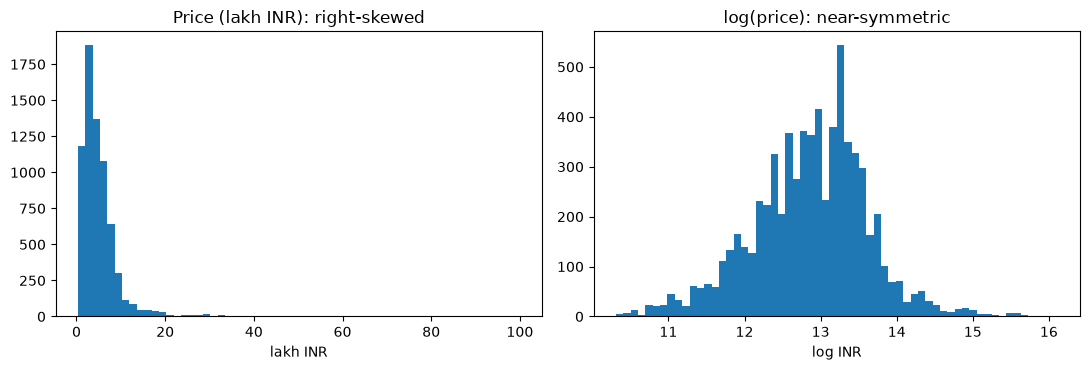

Skewness  raw: 5.57 | log: -0.16


In [9]:
# Cell 9: target distribution and the log transform
from scipy.stats import skew
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df.selling_price / 1e5, bins=60); ax[0].set_title("Price (lakh INR): right-skewed"); ax[0].set_xlabel("lakh INR")
ax[1].hist(np.log(df.selling_price), bins=60); ax[1].set_title("log(price): near-symmetric"); ax[1].set_xlabel("log INR")
plt.tight_layout(); plt.savefig("../reports/figures/price_distribution.png", dpi=120); plt.show()
print("Skewness  raw:", round(skew(df.selling_price), 2), "| log:", round(skew(np.log(df.selling_price)), 2))

**Insight:** raw price has skewness 5.6, because a few luxury cars stretch the tail, and log-price has −0.16. We model **log(price)** for two reasons. A ₹50,000 error means very different things on a ₹1L car and a ₹50L car, and depreciation works in percentages (a car loses roughly a fixed share per year, not a fixed rupee amount). Predictions are converted back with `exp()`, and we report errors in rupees and in percent.

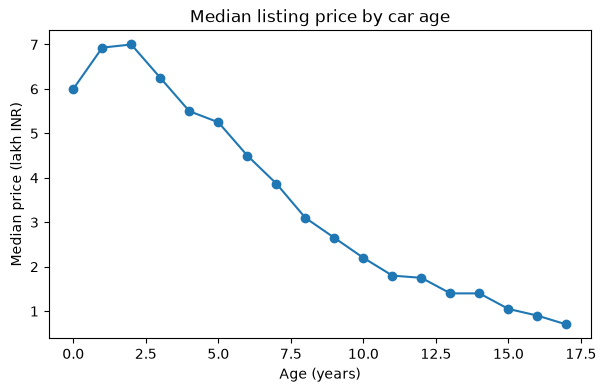

,brand,n,min_age,max_age,naive_annual_dep_%
6,Renault,206,1,9,-0.3
9,Volkswagen,174,0,12,8.5
4,Mahindra,721,0,37,9.5
2,Honda,362,0,18,11.9
8,Toyota,357,0,20,12.5
5,Maruti,2164,0,29,12.5
3,Hyundai,1266,0,21,12.9
0,Chevrolet,216,3,15,13.2
1,Ford,361,0,17,13.9
7,Tata,647,0,21,14.1


In [10]:
# Cell 10: depreciation by age, and a naive per-brand estimate (we will test its weakness next)
import matplotlib.pyplot as plt
med = df.groupby("age").selling_price.agg(median="median", n="size")
med = med[med.n >= 30]                                  # ignore ages with too few cars
plt.figure(figsize=(7, 4)); plt.plot(med.index, med["median"] / 1e5, marker="o")
plt.xlabel("Age (years)"); plt.ylabel("Median price (lakh INR)"); plt.title("Median listing price by car age")
plt.savefig("../reports/figures/price_by_age.png", dpi=120); plt.show()

rows = []
for b, g in df.groupby("brand"):
    if len(g) >= 150:
        slope = np.polyfit(g.age, np.log(g.selling_price), 1)[0]       # slope of log-price per year of age
        rows.append((b, len(g), g.age.min(), g.age.max(), round((1 - np.exp(slope)) * 100, 1)))
brand_dep = pd.DataFrame(rows, columns=["brand", "n", "min_age", "max_age", "naive_annual_dep_%"]).sort_values("naive_annual_dep_%")
display(brand_dep)

In [11]:
# Cell 10b: evidence for the insight below - the age curve and the Renault slope are mix effects
young, new = df[df.age.isin([1, 2])], df[df.age == 0]
print("Maruti share of listings   age 0: %.0f%% | ages 1-2: %.0f%%" % (100 * (new.brand == "Maruti").mean(),
                                                                        100 * (young.brand == "Maruti").mean()))
both = set(new.model_key) & set(young.model_key)
print("Car models present at both age 0 and ages 1-2:", len(both))
display(df[df.model_key.isin(both) & (df.age <= 2)].groupby("age").selling_price.agg(median_price="median", rows="size"))
ren = df[df.brand == "Renault"]
rows = []
for m in ["KWID", "Duster"]:
    g = ren[ren.model == m]
    rows.append((m, len(g), g.age.min(), g.age.max(), round((1 - np.exp(np.polyfit(g.age, np.log(g.selling_price), 1)[0])) * 100, 1)))
display(pd.DataFrame(rows, columns=["Renault model", "n", "min_age", "max_age", "annual_dep_%"]))

Maruti share of listings   age 0: 46% | ages 1-2: 30%
Car models present at both age 0 and ages 1-2: 32


,median_price,rows
age,,
0,600000.0,57
1,610000.0,203
2,620000.0,327


,Renault model,n,min_age,max_age,annual_dep_%
0,KWID,99,1,5,8.2
1,Duster,71,2,8,11.1


**Insight (and a warning about it):** the median price *rises* from age 0 to age 2 (about ₹6.0L to ₹7.0L) before falling. That is not appreciation: Maruti makes up 46% of the age-0 listings against about 30% at ages 1–2, and among the car models that appear at both ages the median price is flat (about ₹6.0L–₹6.2L from age 0 to 2). The curve mixes car type with age. The per-brand slopes have the same problem: Renault shows about 0% depreciation only because its young cars are mostly the cheap KWID (ages 1–5) while its older cars are mostly the pricier Duster (ages 2–8); within each model the slope is about 8% (KWID) and 11% (Duster) a year. **Raw brand comparisons confound age with which models and variants a brand sells.** The next cells separate them.

In [12]:
# Cell 11: mileage looks like it RAISES price - why?
band = df[df.age.between(5, 7)].copy()                  # hold age roughly constant
band["km_quartile"] = pd.qcut(band.km_driven, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
display(band.groupby("km_quartile", observed=True).agg(median_price=("selling_price", "median"),
        diesel_share=("fuel", lambda s: (s == "Diesel").mean()), rows=("fuel", "size")).round(2))

,median_price,diesel_share,rows
km_quartile,,,
Q1 low,420000.0,0.34,521
Q2,450000.0,0.64,399
Q3,465000.0,0.79,457
Q4 high,500000.0,0.91,447


**Insight (a confounding trap):** among 5–7-year-old cars, the *highest*-mileage quartile has the *highest* median price (₹5.0L vs ₹4.2L). Diesel share explains why: it rises from 34% to 91% across the quartiles, and diesel cars are driven more and priced higher. Mileage itself isn't raising prices. A naive plot of price against km would give a wrong story.

In [13]:
# Cell 12: depreciation WITHIN a model (model fixed effects, by de-meaning each variable within model_key)
d = df[df.groupby("model_key")["model_key"].transform("size") >= 10].copy()    # models with >= 10 listings
d["log_price"] = np.log(d.selling_price); d["km_10k"] = d.km_driven / 10_000
d["is_diesel"] = (d.fuel == "Diesel").astype(float); d["is_auto"] = (d.transmission == "Automatic").astype(float)
d["not_first_owner"] = (d.owner != "First Owner").astype(float)
cols = ["age", "km_10k", "is_diesel", "is_auto", "not_first_owner"]
dm = d[cols + ["log_price"]] - d.groupby("model_key")[cols + ["log_price"]].transform("mean")   # remove model identity
beta, *_ = np.linalg.lstsq(dm[cols].values, dm["log_price"].values, rcond=None)
effects = pd.DataFrame({"effect_on_price_%": ((np.exp(beta) - 1) * 100).round(1)}, index=cols)
print("Rows:", len(d), "| models:", d.model_key.nunique()); display(effects)

Rows: 6540 | models: 104


,effect_on_price_%
age,-9.8
km_10k,-0.9
is_diesel,13.6
is_auto,11.3
not_first_owner,-7.7


**Insight:** comparing cars *of the same model*, each extra year of age lowers price by about **9.8%**, and each extra 10,000 km lowers it by only about **0.9%** once age is held fixed. Diesel adds about 13.6%, an automatic gearbox adds about 11.3%, and a non-first owner costs about 7.7%. **Age matters far more than mileage.** These are descriptive associations within models, not causal effects, and the models with few listings are excluded.

## 4. Validation design and baselines
Before fitting anything strong we decide **how we will judge it**. We lock away a final test set made of whole car models the model never sees, tune only on the development set, and compare every model with simple baselines. We also measure how much a careless split would flatter the results.

**Decisions made in this section**
- **Final test set:** 20% of the car models, locked away until the very end.
- **Development validation:** `StratifiedGroupKFold`, grouped by `model_key` (a model never sits on both sides of a split) and stratified by price band (cheap and expensive cars stay balanced).
- **Metrics:** RMSE and R² on log-price (approximate relative error), MAE in rupees (easy to read), and **MedAPE**, the median absolute percentage error (robust to luxury outliers, and the number a buyer cares about).
- **Baselines:** global median, median by age, and a linear model on age and log-mileage.

In [14]:
# Cell 13: target, features, and the locked-away final test set
from sklearn.model_selection import StratifiedGroupKFold
df["log_price"] = np.log(df.selling_price)                       # target (see Section 3)
df["log_km"] = np.log1p(df.km_driven)                            # log of mileage; 1p guards km = 0
NUM = ["age", "km_driven", "engine_cc", "power_bhp", "seats", "mileage_val"]
CAT = ["fuel", "transmission", "owner", "seller_type", "brand"]
price_band = pd.qcut(df.selling_price, 5, labels=False)          # keeps cheap/expensive cars balanced across folds
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, test_idx = next(outer.split(df, price_band, groups=df.model_key))   # first fold = 20% test
dev, test = df.iloc[dev_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print("Development rows:", len(dev), "| Final test rows:", len(test), f"({len(test)/len(df):.1%})")
print("Models shared between dev and test:", len(set(dev.model_key) & set(test.model_key)))
print("Median price  dev:", dev.selling_price.median(), "| test:", test.selling_price.median())

Development rows: 5530 | Final test rows: 1392 (20.1%)
Models shared between dev and test: 0
Median price  dev: 400000.0 | test: 415000.0


In [15]:
# Cell 14: metrics and a cross-validation helper (everything is scored in RUPEE terms after exp())
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
def score(y_log_true, y_log_pred):
    p_true, p_pred = np.exp(y_log_true), np.exp(y_log_pred)
    return {"RMSE_log": np.sqrt(mean_squared_error(y_log_true, y_log_pred)),
            "R2_log": r2_score(y_log_true, y_log_pred),
            "MAE_INR": mean_absolute_error(p_true, p_pred),
            "MedAPE_%": 100 * np.median(np.abs(p_pred - p_true) / p_true)}

def cv_eval(model, data, features, cv):
    """Grouped CV on `data`. Returns mean and std of each metric, plus out-of-fold predictions."""
    X, y, g = data[features], data["log_price"], data["model_key"]
    bands = pd.qcut(data.selling_price, 5, labels=False)
    rows, oof = [], np.zeros(len(data))
    for tr, va in cv.split(X, bands, groups=g):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])           # fit on training folds only
        oof[va] = m.predict(X.iloc[va])
        rows.append(score(y.iloc[va].values, oof[va]))
    r = pd.DataFrame(rows)
    return r.mean(), r.std(), oof

cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)   # development CV, grouped by model

In [16]:
# Cell 15: baseline ladder (grouped CV on the development set)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.base import BaseEstimator, RegressorMixin

class AgeMedian(BaseEstimator, RegressorMixin):
    """Predict the median log-price of cars of the same age (ages above 20 are pooled)."""
    def fit(self, X, y):
        a = X["age"].clip(upper=20)
        self.table_ = pd.Series(np.asarray(y), index=a.values).groupby(level=0).median()
        self.global_ = float(np.median(y)); return self
    def predict(self, X):
        return X["age"].clip(upper=20).map(self.table_).fillna(self.global_).values

baselines = {"B0 global median": (DummyRegressor(strategy="median"), ["age"]),
             "B1 median by age": (AgeMedian(), ["age"]),
             "B2 linear: age + log km": (LinearRegression(), ["age", "log_km"])}
res = {}
for name, (m, feats) in baselines.items():
    mean, std, _ = cv_eval(m, dev, feats, cv_group)
    res[name] = mean
baseline_table = pd.DataFrame(res).T.round(3)
baseline_table

,RMSE_log,R2_log,MAE_INR,MedAPE_%
B0 global median,0.769,-0.004,277822.994,42.857
B1 median by age,0.528,0.526,204502.088,28.954
B2 linear: age + log km,0.528,0.526,205299.901,28.671


**Insight:** knowing only a car's age cuts the typical error from about 43% to 29% (R² on log-price from 0 to 0.53). Adding mileage to a linear model changes almost nothing, which is consistent with Section 3, where 10,000 km cost only about 1% once age is held fixed. These baselines are the bar every later model has to clear: **RMSE_log 0.53, MedAPE about 29%**.

In [17]:
# Cell 16: how much does a careless split flatter the score? (same model, same data, three validation designs)
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold

prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM),     # imputer is fitted inside each fold
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
rf = Pipeline([("prep", prep), ("rf", RandomForestRegressor(n_estimators=150, random_state=0, n_jobs=-1))])

# Duplicates kept, restricted to the same car models as the dev set so that only the duplicates differ
leaky = clean(df_raw[df_raw.columns[:13]], dedupe=False)
leaky = leaky[leaky.km_per_year <= 100_000]
leaky = leaky[leaky.model_key.isin(dev.model_key)].reset_index(drop=True)
leaky["log_price"] = np.log(leaky.selling_price)

def eval_splits(data, splits):
    X, y = data[NUM + CAT], data["log_price"]; out = []
    for tr, va in splits:
        m = clone(rf).fit(X.iloc[tr], y.iloc[tr]); out.append(score(y.iloc[va].values, m.predict(X.iloc[va])))
    return pd.DataFrame(out).mean()

kf = KFold(5, shuffle=True, random_state=1)
bands = pd.qcut(dev.selling_price, 5, labels=False)
leak_demo = pd.DataFrame({
    "1) Duplicates kept, random split": eval_splits(leaky, kf.split(leaky)),
    "2) De-duplicated, random split": eval_splits(dev, kf.split(dev)),
    "3) De-duplicated, grouped by model": eval_splits(dev, cv_group.split(dev, bands, groups=dev.model_key)),
}).T.round(3)
leak_demo

,RMSE_log,R2_log,MAE_INR,MedAPE_%
"1) Duplicates kept, random split",0.215,0.934,66227.942,9.821
"2) De-duplicated, random split",0.236,0.906,78907.180,12.509
"3) De-duplicated, grouped by model",0.332,0.810,116933.980,19.056


**Insight: the same random forest on the same cars gives three very different scores.** Keeping duplicates and splitting randomly gives R² about 0.93 and a typical error near 10%, because the model is tested on rows it has already seen. Removing duplicates drops that to about 0.91 / 12.5%. Holding out whole car models gives about **0.81 / 19%**, which is what the model can do on a model it has never priced. Many submissions report the first number. We report the third and explain the difference. The first two describe a typical repeat listing, and the third is the stress test.

## 5. Models
We now compare model families on the **development set only**; the final test set stays locked. All preprocessing (median imputation with missing-indicators, scaling, one-hot encoding) lives **inside** each pipeline, so it is learned from the training folds only and cannot leak.

**Decisions made in this section**
- **Candidates:** regularised linear models (Ridge, ElasticNet), random forest, and three gradient-boosting libraries (HistGradientBoosting, XGBoost, LightGBM).
- **Features:** age, log-mileage, engine, power, seats, mileage, fuel, transmission, owner, seller type and brand. The model identity (`model_key`) is deliberately **not** a feature: it is only the grouping key for validation.
- **Two validation regimes for every model:** *grouped by car model* (the stress test: pricing a model never seen) and *random on de-duplicated data* (a typical repeat listing, where the model has been seen).
- **Selection rule, stated here and applied mechanically below:** take the best grouped-CV RMSE_log, keep every model within one fold-standard-deviation of it (one-standard-error rule), and among those choose the best typical-listing error.

In [18]:
# Cell 17: features and a leakage-safe pipeline factory
for part in (df, dev, test):                                      # log versions of the two skewed spec columns (helps linear models)
    part["log_engine"] = np.log(part.engine_cc)
    part["log_power"] = np.log(part.power_bhp)
NUM_M = ["age", "log_km", "log_engine", "log_power", "seats", "mileage_val"]
CAT_M = ["fuel", "transmission", "owner", "seller_type", "brand"]
FEATS = NUM_M + CAT_M                                             # model identity (model_key) is NOT a feature: it is only the grouping key

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipe(model, scale=False):
    """Preprocessing + model in ONE pipeline, so imputation/scaling/encoding are learned from training folds only."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),      # fill gaps, and flag which were gaps
                    ("scale", StandardScaler() if scale else "passthrough")])
    cols = ColumnTransformer([("num", num, NUM_M),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_M)])
    return Pipeline([("cols", cols), ("model", model)])

In [19]:
# Cell 18: candidate models, each scored in two regimes
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

candidates = {
    "Ridge": make_pipe(RidgeCV(alphas=np.logspace(-2, 2, 15)), scale=True),
    "ElasticNet": make_pipe(ElasticNetCV(l1_ratio=[.2, .5, .8], alphas=np.logspace(-4, -1, 12), cv=5, max_iter=5000), scale=True),
    "RandomForest": make_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0)),
    "HistGradientBoosting": make_pipe(HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)),
    "XGBoost": make_pipe(XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                      min_child_weight=3, reg_lambda=2.0, random_state=0, n_jobs=-1)),
    "LightGBM": make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                        colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0, random_state=0, n_jobs=-1, verbose=-1)),
}
seen_cv = KFold(5, shuffle=True, random_state=1)                  # regime 2: random split of de-duplicated data (typical repeat listing)

def both_regimes(model):
    g_mean, g_std, _ = cv_eval(model, dev, FEATS, cv_group)       # regime 1: grouped by car model (stress test)
    rows = []
    for tr, va in seen_cv.split(dev):
        m = clone(model).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr])
        rows.append(score(dev.log_price.iloc[va].values, m.predict(dev[FEATS].iloc[va])))
    s = pd.DataFrame(rows).mean()
    return {"grouped_RMSE_log": g_mean["RMSE_log"], "grouped_std": g_std["RMSE_log"], "grouped_MedAPE_%": g_mean["MedAPE_%"],
            "grouped_R2": g_mean["R2_log"], "seen_MedAPE_%": s["MedAPE_%"], "seen_R2": s["R2_log"]}

results = pd.DataFrame({name: both_regimes(m) for name, m in candidates.items()}).T
results.round(3)

,grouped_RMSE_log,grouped_std,grouped_MedAPE_%,grouped_R2,seen_MedAPE_%,seen_R2
Ridge,0.280,0.018,16.824,0.866,15.141,0.888
ElasticNet,0.280,0.019,16.865,0.866,15.135,0.888
RandomForest,0.311,0.050,18.148,0.832,12.070,0.913
HistGradientBoosting,0.292,0.037,16.951,0.852,11.971,0.915
XGBoost,0.289,0.032,16.666,0.856,12.301,0.915
LightGBM,0.294,0.038,17.649,0.851,11.866,0.916


**Insight: the best model depends on the question.** On unseen car models, Ridge and ElasticNet are best (RMSE_log 0.280, typical error about 17%), XGBoost, HistGradientBoosting and LightGBM are close behind (0.289–0.294), and the random forest is worst and least stable (0.311, fold standard deviation 0.050). With fold standard deviations of 0.02–0.04, everything except the forest is statistically indistinguishable on this test. On a typical repeat listing the order flips: boosting and the forest reach about 12% median error against about 15% for the linear models. Linear models extrapolate well to unseen models but cannot capture the interactions that matter once a model has been seen.

In [20]:
# Cell 19: the selection rule, applied mechanically
best_name = results.grouped_RMSE_log.idxmin()
threshold = results.loc[best_name, "grouped_RMSE_log"] + results.loc[best_name, "grouped_std"]       # one-standard-error rule
shortlist = results[results.grouped_RMSE_log <= threshold]
chosen = shortlist["seen_MedAPE_%"].idxmin()
print(f"Best on the stress test: {best_name} (RMSE_log {results.loc[best_name, 'grouped_RMSE_log']:.3f}); threshold = {threshold:.3f}")
print("Shortlist (statistically indistinguishable on the stress test):", list(shortlist.index))
print("Chosen (best typical-listing MedAPE among the shortlist):", chosen)

Best on the stress test: Ridge (RMSE_log 0.280); threshold = 0.298
Shortlist (statistically indistinguishable on the stress test): ['Ridge', 'ElasticNet', 'HistGradientBoosting', 'XGBoost', 'LightGBM']
Chosen (best typical-listing MedAPE among the shortlist): LightGBM


**Decision:** the rule picks **LightGBM**. Its edge over HistGradientBoosting on the typical-listing error is about 0.1 percentage points, which is not a meaningful gap; we take LightGBM because it supports native quantile regression (for the prediction intervals in the next sections) and works directly with SHAP. The final test set has not been touched.

In [21]:
# Cell 20: did our model-aware imputation idea (Section 3) actually help?
from sklearn.base import BaseEstimator, TransformerMixin
class ModelAwareFill(BaseEstimator, TransformerMixin):
    """Our first idea: fill missing specs from the same model+fuel, falling back to brand+fuel, then fuel, then global."""
    SPECS = ["log_engine", "log_power", "seats", "mileage_val"]
    LEVELS = [["model_key", "fuel"], ["brand", "fuel"], ["fuel"]]
    def fit(self, X, y=None):
        self.tables_ = [(lv, X.groupby(lv)[self.SPECS].median()) for lv in self.LEVELS]
        self.global_ = X[self.SPECS].median(); return self
    def transform(self, X):
        X = X.copy()
        for lv, tab in self.tables_:
            idx = pd.MultiIndex.from_frame(X[lv]) if len(lv) > 1 else pd.Index(X[lv[0]])
            fill = tab.reindex(idx); fill.index = X.index
            for c in self.SPECS: X[c] = X[c].fillna(fill[c])
        for c in self.SPECS: X[c] = X[c].fillna(self.global_[c])
        return X

def with_fill(model, scale=False):
    return Pipeline([("fill", ModelAwareFill()), ("rest", make_pipe(model, scale))])

abl = {}
for name, plain, aware in [("Ridge", candidates["Ridge"], with_fill(RidgeCV(alphas=np.logspace(-2, 2, 15)), scale=True)),
                           ("LightGBM", candidates["LightGBM"], with_fill(clone(candidates["LightGBM"].named_steps["model"])))]:
    feats_aware = FEATS + ["model_key"]                           # the aware filler needs the model key
    m_plain, _, _ = cv_eval(plain, dev, FEATS, cv_group)
    m_aware, _, _ = cv_eval(aware, dev, feats_aware, cv_group)
    abl[name] = {"median fill: RMSE_log": m_plain["RMSE_log"], "model-aware fill: RMSE_log": m_aware["RMSE_log"],
                 "median fill: MedAPE_%": m_plain["MedAPE_%"], "model-aware fill: MedAPE_%": m_aware["MedAPE_%"]}
pd.DataFrame(abl).T.round(4)

,median fill: RMSE_log,model-aware fill: RMSE_log,median fill: MedAPE_%,model-aware fill: MedAPE_%
Ridge,0.2800,0.2796,16.8242,16.8645
LightGBM,0.2943,0.2964,17.6495,17.0875


**Insight: our own idea did not help.** In Section 3 we proposed filling missing specs from the same model and fuel. Against plain median filling the difference is within noise (Ridge RMSE_log 0.2796 vs 0.2800, LightGBM 0.2964 vs 0.2943, against fold standard deviations of 0.02–0.04), and it is not consistently better on MedAPE either. The simpler pipeline stays: median filling plus missing-indicator columns, which keep the "old and cheap" signal found in Section 3. Reporting a reasonable idea that did not pay off is part of the evidence.

In [22]:
# Cell 21: how complex should the trees be?
rows = {}
for leaves in [4, 8, 15, 31]:
    m = make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=leaves, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0, random_state=0, n_jobs=-1, verbose=-1))
    r = both_regimes(m)
    rows[f"LightGBM, {leaves} leaves"] = {"grouped_RMSE_log": r["grouped_RMSE_log"], "grouped_MedAPE_%": r["grouped_MedAPE_%"], "seen_MedAPE_%": r["seen_MedAPE_%"]}
pd.DataFrame(rows).T.round(3)

,grouped_RMSE_log,grouped_MedAPE_%,seen_MedAPE_%
"LightGBM, 4 leaves",0.287,16.852,13.503
"LightGBM, 8 leaves",0.288,16.773,12.307
"LightGBM, 15 leaves",0.294,17.649,11.866
"LightGBM, 31 leaves",0.302,17.832,11.631


**Insight: complexity trades one regime against the other.** Shallower trees do slightly better on unseen models (RMSE_log 0.287 with 4 leaves against 0.302 with 31) but clearly worse on repeat listings (13.5% against 11.6% median error). We keep **15 leaves**: it is the most complex setting that still sits inside the one-standard-deviation band of the stress test (0.298), so it takes the best typical-listing result without giving up robustness. Selection used the same grouped folds as the reporting, so the numbers are slightly optimistic; the locked test set is the honest check.

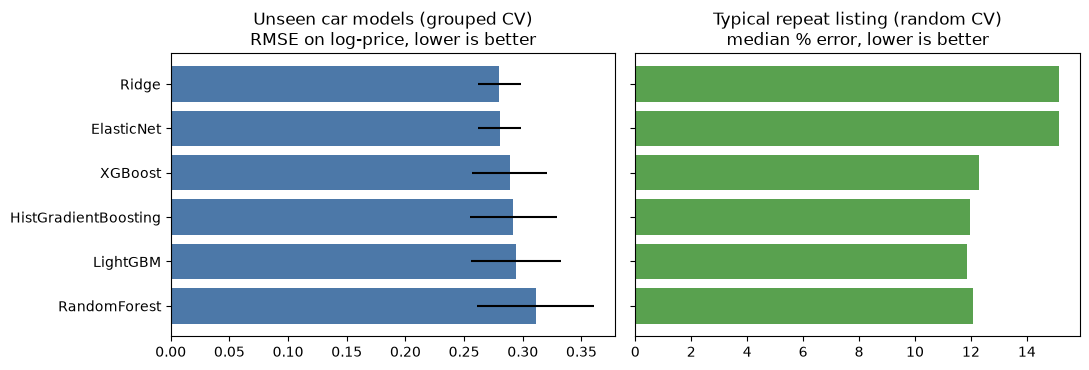

In [23]:
# Cell 22: comparison figure
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = results.sort_values("grouped_RMSE_log").index
ax[0].barh(order, results.loc[order, "grouped_RMSE_log"], xerr=results.loc[order, "grouped_std"], color="#4C78A8")
ax[0].set_title("Unseen car models (grouped CV)\nRMSE on log-price, lower is better"); ax[0].invert_yaxis()
ax[1].barh(order, results.loc[order, "seen_MedAPE_%"], color="#59A14F")
ax[1].set_title("Typical repeat listing (random CV)\nmedian % error, lower is better")
plt.tight_layout(); plt.savefig("../reports/figures/model_comparison.png", dpi=120); plt.show()

**Section 5 summary:** model = LightGBM (15 leaves, 500 trees, learning rate 0.03) inside the leakage-safe pipeline. Next we look at *where* it is wrong (error analysis), explain it with SHAP, and build the prediction intervals and the Deal Score.